# Phase 3 — URL-Only Feature Engineering & Empirical Analysis
**Project:** Explainable and Generalization-Aware Phishing URL Detection Using Machine Learning and SHAP

This notebook performs a comprehensive empirical analysis of our 68 engineered URL-only features across both research datasets:
1. **Primary Dataset (LegitPhish):** 101,218 processed records.
2. **External Validation Dataset (PhiUSIIL):** 235,795 processed records.

**Strict Research Constraints:**
- All 68 features are derived exclusively from the URL string offline before any network connection is made.
- Zero reliance on HTML source code, DOM structure, page titles, DNS, or WHOIS lookups.
- No model training or predictive performance metrics are computed in this phase.


In [1]:
import sys
from pathlib import Path

# Add project root to sys.path
cwd = Path.cwd().resolve()
if (cwd / "src").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "src").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.features.feature_config import (
    FEATURE_NAMES,
    FEATURE_DTYPES,
    FEATURE_CATEGORIES,
    TOTAL_FEATURE_COUNT,
    SUSPICIOUS_KEYWORDS
)
from src.features.feature_extractor import (
    extract_url_features,
    extract_features_dataframe
)

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 1000)
print(f"Loaded feature configuration: {TOTAL_FEATURE_COUNT} URL-only features defined.")


Loaded feature configuration: 68 URL-only features defined.


In [2]:
# Load processed feature matrices and metadata tables
legit_feat_path = PROJECT_ROOT / "data" / "processed" / "legitphish" / "url_features.csv"
legit_meta_path = PROJECT_ROOT / "data" / "processed" / "legitphish" / "metadata.csv"

phi_feat_path = PROJECT_ROOT / "data" / "processed" / "phiusil" / "url_features.csv"
phi_meta_path = PROJECT_ROOT / "data" / "processed" / "phiusil" / "metadata.csv"

df_legit_feat = pd.read_csv(legit_feat_path)
df_legit_meta = pd.read_csv(legit_meta_path)

df_phi_feat = pd.read_csv(phi_feat_path)
df_phi_meta = pd.read_csv(phi_meta_path)

print(f"LegitPhish Features Matrix: {df_legit_feat.shape[0]:,} rows x {df_legit_feat.shape[1]} columns")
print(f"PhiUSIIL Features Matrix:   {df_phi_feat.shape[0]:,} rows x {df_phi_feat.shape[1]} columns")


LegitPhish Features Matrix: 101,218 rows x 69 columns
PhiUSIIL Features Matrix:   235,795 rows x 69 columns


In [3]:
# Verify identical feature schema and zero missing values
assert list(df_legit_feat.columns) == list(df_phi_feat.columns), "Feature schema mismatch!"
print(f"Common Feature Schema: {len(FEATURE_NAMES)} features + 1 target label = {df_legit_feat.shape[1]} columns")

missing_legit = df_legit_feat.isnull().sum().sum()
missing_phi = df_phi_feat.isnull().sum().sum()
print(f"Missing values in LegitPhish features: {missing_legit}")
print(f"Missing values in PhiUSIIL features:   {missing_phi}")

# Categorical vs Numerical breakdown
cat_counts = pd.Series(FEATURE_CATEGORIES).value_counts()
print("\nFeature Count by Category:")
for cat, count in cat_counts.items():
    print(f"  - {cat:20s}: {count:2d} features")


Common Feature Schema: 68 features + 1 target label = 69 columns
Missing values in LegitPhish features: 0
Missing values in PhiUSIIL features:   0

Feature Count by Category:
  - character           : 20 features
  - lexical_pattern     : 12 features
  - hostname            :  9 features
  - path                :  9 features
  - protocol            :  8 features
  - length              :  5 features
  - query               :  5 features


In [4]:
# Demonstrate deterministic feature extraction on sample URLs
test_urls = [
    "https://login.paypal.com/signin",
    "http://192.168.1.1:8080/admin/login.php",
    "https://secure-banking-update.verification-service.com/auth?token=987654321",
    "https://www.wikipedia.org/wiki/Phishing"
]

demo_df = extract_features_dataframe(test_urls)
demo_df.index = [f"URL_{i+1}" for i in range(len(test_urls))]

key_cols = [
    "url_length", "hostname_length", "url_entropy", "is_ip_address",
    "subdomain_count", "path_segment_count", "suspicious_keyword_count", "is_https"
]
print("Feature Extraction Demonstration (Selected Key Columns):")
display(demo_df[key_cols])


Feature Extraction Demonstration (Selected Key Columns):
       url_length  hostname_length  url_entropy  is_ip_address  subdomain_count  path_segment_count  suspicious_keyword_count  is_https
URL_1          31               16       3.8890              0                1                   1                         2         1
URL_2          39               11       4.1185              1                0                   2                         1         0
URL_3          75               46       4.7715              0                1                   1                         3         1
URL_4          39               17       3.8491              0                1                   2                         0         1


In [5]:
# Compare class-wise means on LegitPhish (0 = Phishing, 1 = Legitimate)
class_means_l = df_legit_feat.groupby("label")[key_cols].mean().round(3)
class_means_l.index = ["Phishing (0)", "Legitimate (1)"]

print("LegitPhish: Feature Means by Class:")
display(class_means_l)

# Compare class-wise means on PhiUSIIL
class_means_p = df_phi_feat.groupby("label")[key_cols].mean().round(3)
class_means_p.index = ["Phishing (0)", "Legitimate (1)"]

print("\nPhiUSIIL: Feature Means by Class:")
display(class_means_p)


LegitPhish: Feature Means by Class:
                url_length  hostname_length  url_entropy  is_ip_address  subdomain_count  path_segment_count  suspicious_keyword_count  is_https
Phishing (0)        39.412           15.161        4.045          0.771            0.221               1.327                     0.019     0.055
Legitimate (1)      27.681           19.172        3.859          0.000            1.052               0.032                     0.001     1.000

PhiUSIIL: Feature Means by Class:
                url_length  hostname_length  url_entropy  is_ip_address  subdomain_count  path_segment_count  suspicious_keyword_count  is_https
Phishing (0)        46.239           24.462        4.106          0.006            1.134               0.589                     0.079     0.487
Legitimate (1)      27.229           19.229        3.853          0.000            1.057               0.000                     0.001     1.000


In [6]:
# Compute Pearson correlation with the binary class label on LegitPhish
# Label: 0 = Phishing, 1 = Legitimate
# Negative correlation indicates positive association with Phishing (0)
corr_series = df_legit_feat[FEATURE_NAMES].apply(lambda col: col.corr(df_legit_feat["label"]))

top_phishing_associated = corr_series.sort_values().head(8)
top_legitimate_associated = corr_series.sort_values(ascending=False).head(8)

print("Top Features Associated with Phishing (Lowest Correlation with Legitimate Label 1):")
for feat, val in top_phishing_associated.items():
    print(f"  {feat:30s}: r = {val:.4f}")

print("\nTop Features Associated with Legitimate URLs (Highest Correlation with Label 1):")
for feat, val in top_legitimate_associated.items():
    print(f"  {feat:30s}: r = {val:.4f}")


Top Features Associated with Phishing (Lowest Correlation with Legitimate Label 1):
  is_http                       : r = -0.9292
  digit_ratio                   : r = -0.8156
  digit_count                   : r = -0.7577
  is_ip_address                 : r = -0.7447
  hostname_has_digits           : r = -0.7348
  path_segment_count            : r = -0.7188
  slash_count                   : r = -0.7121
  dot_count                     : r = -0.6914

Top Features Associated with Legitimate URLs (Highest Correlation with Label 1):
  is_path_empty                 : r = 0.9803
  is_https                      : r = 0.9292
  protocol_type                 : r = 0.9292
  alpha_ratio                   : r = 0.7777
  max_consecutive_repeated_char : r = 0.7488
  subdomain_count               : r = 0.6072
  max_hostname_label_length     : r = 0.5098
  avg_hostname_label_length     : r = 0.4741


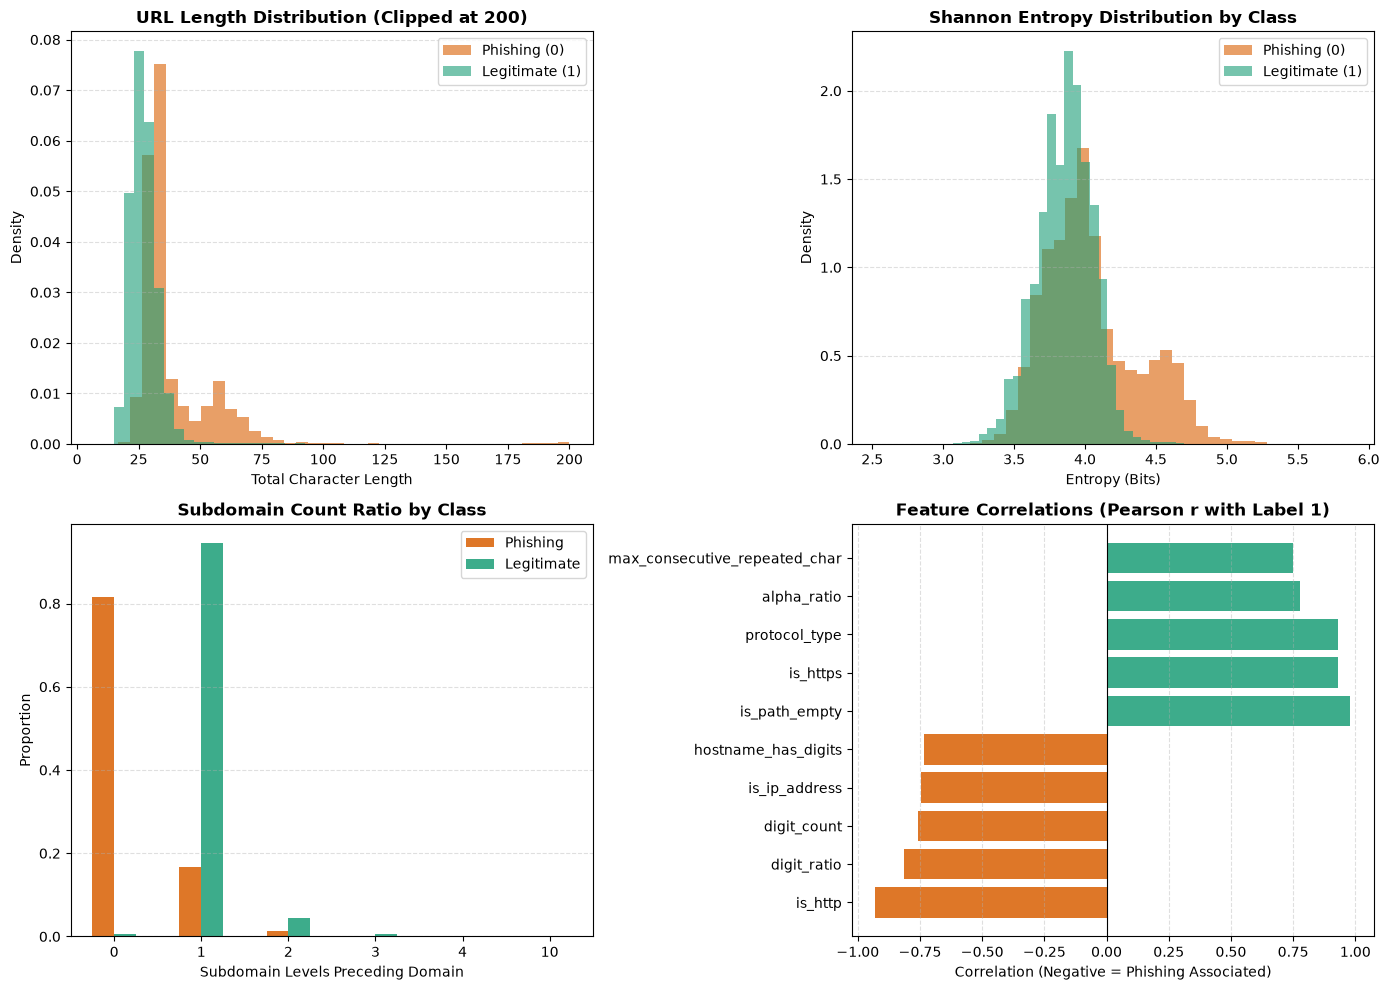

In [7]:
# Generate comparative visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. URL Length Distribution by Class (LegitPhish)
phish_lens = df_legit_feat[df_legit_feat["label"] == 0]["url_length"].clip(upper=200)
legit_lens = df_legit_feat[df_legit_feat["label"] == 1]["url_length"].clip(upper=200)

axes[0, 0].hist(phish_lens, bins=40, alpha=0.6, label="Phishing (0)", color="#d95f02", density=True)
axes[0, 0].hist(legit_lens, bins=40, alpha=0.6, label="Legitimate (1)", color="#1b9e77", density=True)
axes[0, 0].set_title("URL Length Distribution (Clipped at 200)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Total Character Length")
axes[0, 0].set_ylabel("Density")
axes[0, 0].legend()
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.4)

# 2. Shannon Entropy Distribution by Class (LegitPhish)
phish_ent = df_legit_feat[df_legit_feat["label"] == 0]["url_entropy"]
legit_ent = df_legit_feat[df_legit_feat["label"] == 1]["url_entropy"]

axes[0, 1].hist(phish_ent, bins=40, alpha=0.6, label="Phishing (0)", color="#d95f02", density=True)
axes[0, 1].hist(legit_ent, bins=40, alpha=0.6, label="Legitimate (1)", color="#1b9e77", density=True)
axes[0, 1].set_title("Shannon Entropy Distribution by Class", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Entropy (Bits)")
axes[0, 1].set_ylabel("Density")
axes[0, 1].legend()
axes[0, 1].grid(axis="y", linestyle="--", alpha=0.4)

# 3. Subdomain Count by Class
sub_phish = df_legit_feat[df_legit_feat["label"] == 0]["subdomain_count"].value_counts(normalize=True).head(5)
sub_legit = df_legit_feat[df_legit_feat["label"] == 1]["subdomain_count"].value_counts(normalize=True).head(5)
sub_df = pd.DataFrame({"Phishing": sub_phish, "Legitimate": sub_legit}).fillna(0)

sub_df.plot(kind="bar", ax=axes[1, 0], color=["#d95f02", "#1b9e77"], alpha=0.85)
axes[1, 0].set_title("Subdomain Count Ratio by Class", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Subdomain Levels Preceding Domain")
axes[1, 0].set_ylabel("Proportion")
axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(), rotation=0)
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.4)

# 4. Top Feature Correlations with Phishing
top_corr = pd.concat([top_phishing_associated.head(5), top_legitimate_associated.head(5)])
colors = ["#d95f02" if x < 0 else "#1b9e77" for x in top_corr.values]
axes[1, 1].barh(top_corr.index, top_corr.values, color=colors, alpha=0.85)
axes[1, 1].set_title("Feature Correlations (Pearson r with Label 1)", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Correlation (Negative = Phishing Associated)")
axes[1, 1].axvline(0, color="black", linestyle="-", linewidth=0.8)
axes[1, 1].grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


In [8]:
# Inspect domain distributions in metadata tables
doms_l = df_legit_meta["registrable_domain"].dropna().value_counts()
doms_p = df_phi_meta["registrable_domain"].dropna().value_counts()

print(f"LegitPhish Unique Domains: {len(doms_l):,}")
print(f"PhiUSIIL Unique Domains:   {len(doms_p):,}")

# Overlapping domains
overlap_doms = set(doms_l.index).intersection(set(doms_p.index))
print(f"Domain Overlap:            {len(overlap_doms):,} domains ({len(overlap_doms)/len(doms_l)*100:.2f}% of LegitPhish)")

# Top domains in PhiUSIIL (cloud platforms)
print("\nTop 5 Repeated Domains in PhiUSIIL (Multi-Tenant Cloud Services):")
print(doms_p.head(5))


LegitPhish Unique Domains: 62,151
PhiUSIIL Unique Domains:   172,296
Domain Overlap:            35,924 domains (57.80% of LegitPhish)

Top 5 Repeated Domains in PhiUSIIL (Multi-Tenant Cloud Services):
registrable_domain
web.app            5754
firebaseapp.com    5594
repl.co            3754
weeblysite.com     3097
ipfs.io            1559
Name: count, dtype: int64


## Phase 3 Conclusions and Next Steps
1. **URL-Only Independence:** All 68 features are extracted strictly from URL strings without network requests, HTML analysis, or DNS queries.
2. **Deterministic Schema:** Both LegitPhish (101,218 rows) and PhiUSIIL (235,795 rows) share an identical feature schema with zero missing values.
3. **Data Leakage Mitigation:** Predictive features are strictly separated from domain identities and dataset provenance. In Phase 4, domain-disjoint cross-validation and purged external evaluation will prevent memorization of the 35,925 overlapping domains.
